# Identifying Patterns in Global E-Commerce Sales
### Customer Segmentation of a UK Online Retailer with RFM and K-Means

**Course:** DSAI501 - Machine Learning and Data Science

This notebook runs the full data-science lifecycle on the *Online Retail II* dataset: load → clean at scale →
explore → engineer RFM features → segment customers with K-Means → check the model (baseline, stability, returns)
→ translate the segments into business actions, plus a market-basket add-on. Outputs are saved below so the
notebook can be read without re-running.


## 0. Environment and reproducibility
A fixed random seed makes every result reproducible.

In [1]:
import os, textwrap, warnings, json
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, adjusted_rand_score
import joblib
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
%matplotlib inline

RNG = 42
np.random.seed(RNG)
DATA_PATH = "../data/online_retail_II.xlsx"   # download from UCI (see README) and place here
FIGDIR = "../figures"; MODELDIR = "../models"; DATADIR = "../data"
for d in (FIGDIR, MODELDIR): os.makedirs(d, exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


In [2]:
# ---- Visual style: standard seaborn (whitegrid) + Okabe-Ito colorblind-safe palette ----
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
ACCENT="#0072B2"; INK="#222222"; INK2="#555555"; MUTED="#888888"; GRID="#DDDDDD"
CL=["#0072B2","#E69F00","#009E73","#CC79A7"]   # Okabe-Ito (colorblind-safe)
def style_ax(ax): return ax
def make_fig(title, subtitle=None, figsize=(8.0,4.8)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(title, fontsize=12.5, fontweight="bold", loc="left", pad=10)
    return fig, ax
def gbp(x,_=None):
    a=abs(x); return (f"£{x/1e6:.1f}M" if a>=1e6 else f"£{x/1e3:.0f}k" if a>=1e3 else f"£{x:.0f}")
def save_show(fig,name):
    try: fig.tight_layout()
    except Exception: pass
    fig.savefig(os.path.join(FIGDIR,name), dpi=150, bbox_inches="tight"); plt.show()

## 1. Load the data
The dataset ships as one Excel workbook with two sheets (2009-2010 and 2010-2011). We read both and stack them,
tagging each row with its source sheet.

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)
frames=[]
for name, d in sheets.items():
    d=d.copy(); d["SourceSheet"]=name; frames.append(d); print(f"{name}: {d.shape}")
raw = pd.concat(frames, ignore_index=True)
raw.columns=[c.strip() for c in raw.columns]
for c in ["Invoice","StockCode","Description","Country"]: raw[c]=raw[c].astype("string")
print("Combined:", raw.shape)
raw.head()

Year 2009-2010: (525461, 9)
Year 2010-2011: (541910, 9)


Combined: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


## 2. Data description
Before cleaning, we quantify exactly what is wrong with the raw data.

In [4]:
print("Date range:", raw['InvoiceDate'].min(), "->", raw['InvoiceDate'].max())
print("Unique invoices:", raw['Invoice'].nunique(), "| unique StockCodes:", raw['StockCode'].nunique(),
      "| countries:", raw['Country'].nunique())
display(pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean()*100).round(2)}))
print("Cancellations (Invoice starts 'C'):", int(raw['Invoice'].str.startswith('C').sum()))
print("Quantity <= 0:", int((raw['Quantity']<=0).sum()), "| Price <= 0:", int((raw['Price']<=0).sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
# the two sheets overlap at the Dec-2010 boundary: check how many invoices appear in BOTH
s1=set(raw.loc[raw['SourceSheet']=='Year 2009-2010','Invoice']); s2=set(raw.loc[raw['SourceSheet']=='Year 2010-2011','Invoice'])
print("Invoices appearing in BOTH sheets (boundary overlap):", len(s1 & s2))

Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Unique invoices: 53628 | unique StockCodes: 5305 | countries: 43


,missing,missing_%
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00
SourceSheet,0,0.00


Cancellations (Invoice starts 'C'): 19494
Quantity <= 0: 22950 | Price <= 0: 6207


Exact duplicate rows: 12133


Invoices appearing in BOTH sheets (boundary overlap): 1088


## 3. Data cleaning at scale
We remove the issues in a documented sequence and record how many rows each rule drops. Each decision has a reason:

- **Duplicates**: dropped on *transaction content* (not a naive row match), so the ~1,000 invoices that appear in **both** sheets at the Dec-2010 boundary are counted once, not twice.
- **Cancellations** (Invoice starting `C`): returns; we model purchasing, so we exclude them (return impact is quantified later).
- **Non-product StockCodes** (`POST`, `DOT`, `M`, `BANK CHARGES`, `AMAZONFEE`, `TEST001`, `gift_*`, ...): fees/adjustments.
- **Quantity ≤ 0 / Price ≤ 0**: returns, give-aways and adjustments. (Most negative quantities belong to cancellations already removed, so these steps show only the *residual*.)
- **Missing Customer ID**: cannot be tied to a customer, and customer-level segmentation needs an identifiable customer.

In [5]:
wf=[{"step":"Raw (both sheets)","removed":0,"remaining":len(raw)}]
df=raw.copy()
def step(name, keep):
    global df
    before=len(df); df=df.loc[keep].copy(); wf.append({"step":name,"removed":before-len(df),"remaining":len(df)})
TXCOLS=["Invoice","StockCode","Description","Quantity","InvoiceDate","Price","Customer ID","Country"]
step("Drop duplicate rows (incl. sheet overlap)", ~df.duplicated(subset=TXCOLS))
step("Drop cancellations (Invoice 'C')", ~df["Invoice"].str.startswith("C").fillna(False))
step("Keep product StockCodes only", df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$").fillna(False))
step("Drop Quantity <= 0", df["Quantity"]>0)
step("Drop Price <= 0", df["Price"]>0)
step("Drop missing Customer ID", df["Customer ID"].notna())
df["Customer ID"]=df["Customer ID"].astype(int); df["Revenue"]=df["Quantity"]*df["Price"]
display(pd.DataFrame(wf))
print(f"Cleaned: {len(df):,} rows | {df['Customer ID'].nunique():,} customers | "
      f"{df['Invoice'].nunique():,} invoices | revenue £{df['Revenue'].sum():,.0f}")

,step,removed,remaining
0,Raw (both sheets),0,1067371
1,Drop duplicate rows (incl. sheet overlap),34335,1033036
2,Drop cancellations (Invoice 'C'),19104,1013932
3,Keep product StockCodes only,4791,1009141
4,Drop Quantity <= 0,3362,1005779
5,Drop Price <= 0,2566,1003213
6,Drop missing Customer ID,226636,776577


Cleaned: 776,577 rows | 5,852 customers | 36,594 invoices | revenue £17,068,568


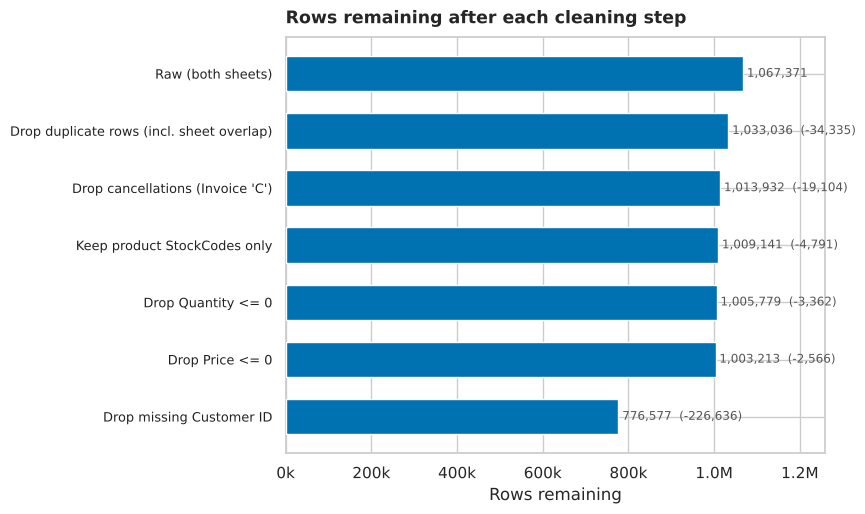

In [6]:
fig,ax=make_fig("Rows remaining after each cleaning step",
                "Each bar shows the rows left after applying the rule on the left. De-duplication is on transaction content.",
                figsize=(8.6,5.3))
yp=np.arange(len(wf))[::-1]
ax.barh(yp,[w["remaining"] for w in wf],color=ACCENT,height=0.62,zorder=3)
ax.set_yticks(yp); ax.set_yticklabels([w["step"] for w in wf],fontsize=9.3,color=INK)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:f"{x/1e6:.1f}M" if x>=1e6 else f"{x/1e3:.0f}k"))
for y,w in zip(yp,wf):
    ax.text(w["remaining"]+9000,y,f"{w['remaining']:,}"+(f"  (-{w['removed']:,})" if w['removed'] else ""),va="center",fontsize=8.6,color=INK2)
ax.set_xlim(0,max(w['remaining'] for w in wf)*1.18); ax.set_xlabel("Rows remaining")
save_show(fig,"01_cleaning_waterfall.png")

In [7]:
# How much revenue sits with UNIDENTIFIED customers? (a key limitation, computed not assumed)
pm=raw["StockCode"].str.match(r"^\d{5}[A-Za-z]*$").fillna(False)
valid=pm & (raw["Quantity"]>0) & (raw["Price"]>0) & (~raw["Invoice"].str.startswith("C").fillna(False))
rev_valid=(raw.loc[valid,"Quantity"]*raw.loc[valid,"Price"]).sum()
unident=valid & raw["Customer ID"].isna()
rev_unident=(raw.loc[unident,"Quantity"]*raw.loc[unident,"Price"]).sum()
rows_missing_pct=raw["Customer ID"].isna().mean()*100
print(f"Unidentified transactions: {rows_missing_pct:.1f}% of ALL raw rows, "
      f"but only {rev_unident/rev_valid*100:.1f}% of valid revenue -> anonymous buyers skew small and one-off.")

Unidentified transactions: 22.8% of ALL raw rows, but only 13.3% of valid revenue -> anonymous buyers skew small and one-off.


## 4. Exploratory data analysis
Four views tell the story: *when* revenue comes in, *where* it comes from, *how concentrated* it is, and *what* sells.
These views use the cleaned, identified-customer transactions.

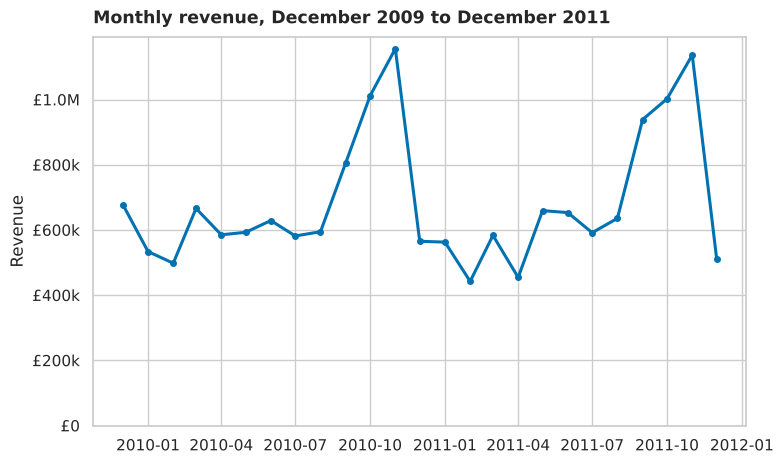

In [8]:
m=df.set_index("InvoiceDate")["Revenue"].resample("MS").sum()
fig,ax=make_fig("Monthly revenue, December 2009 to December 2011",
                "Identified-customer transactions. The first and last months are partial.")
ax.plot(m.index,m.values,color=ACCENT,lw=2.2,zorder=3); ax.scatter(m.index,m.values,color=ACCENT,s=16,zorder=4)
ax.yaxis.set_major_formatter(FuncFormatter(gbp)); ax.set_ylim(0,None); ax.set_ylabel("Revenue")
save_show(fig,"02_monthly_revenue.png")

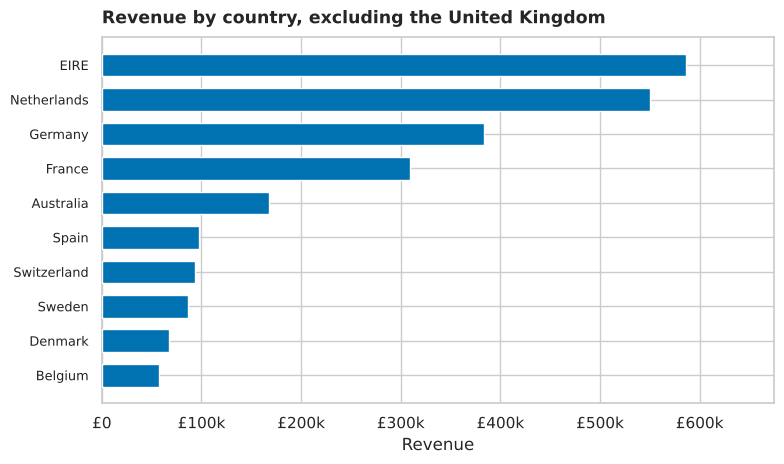

In [9]:
cr=df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk=cr["United Kingdom"]; exuk=cr.drop("United Kingdom").head(10)[::-1]
fig,ax=make_fig("Revenue by country, excluding the United Kingdom",
                f"Top 10 non-UK markets. The UK accounts for £{uk/1e6:.1f}M, {uk/cr.sum()*100:.0f}% of revenue, and is shown separately.")
ax.barh(np.arange(len(exuk)),exuk.values,color=ACCENT,height=0.66,zorder=3)
ax.set_yticks(np.arange(len(exuk))); ax.set_yticklabels(exuk.index,fontsize=9.3,color=INK)
ax.xaxis.set_major_formatter(FuncFormatter(gbp)); ax.set_xlim(0,exuk.max()*1.15); ax.set_xlabel("Revenue")
save_show(fig,"03_revenue_by_country_exuk.png")

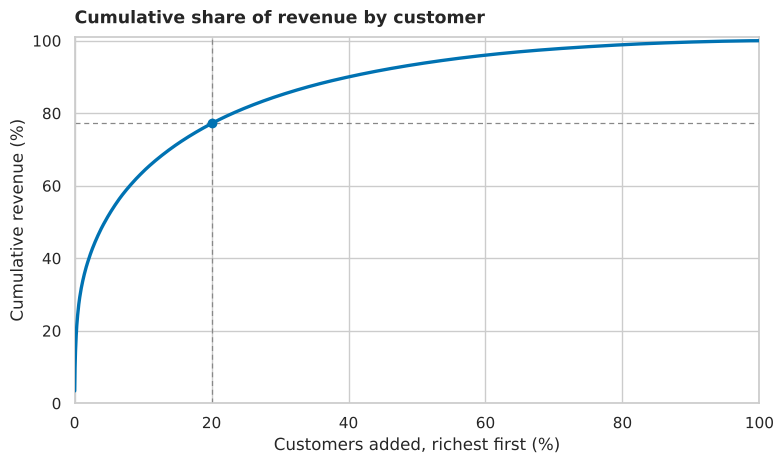

In [10]:
cust_rev=df.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False)
cum=cust_rev.cumsum()/cust_rev.sum()*100; xp=(np.arange(1,len(cust_rev)+1)/len(cust_rev))*100
top20=cum.iloc[int(np.ceil(0.2*len(cust_rev)))-1]
fig,ax=make_fig("Cumulative share of revenue by customer",
                f"Customers ordered by total spend, highest first. The top 20% account for {top20:.0f}% of revenue.")
ax.plot(xp,cum.values,color=ACCENT,lw=2.4,zorder=3)
ax.axvline(20,color=MUTED,lw=0.9,ls=(0,(4,3))); ax.axhline(top20,color=MUTED,lw=0.9,ls=(0,(4,3)))
ax.scatter([20],[top20],color=ACCENT,s=36,zorder=5)
ax.set_xlim(0,100); ax.set_ylim(0,101); ax.set_xlabel("Customers added, richest first (%)"); ax.set_ylabel("Cumulative revenue (%)")
save_show(fig,"04_pareto_customers.png")

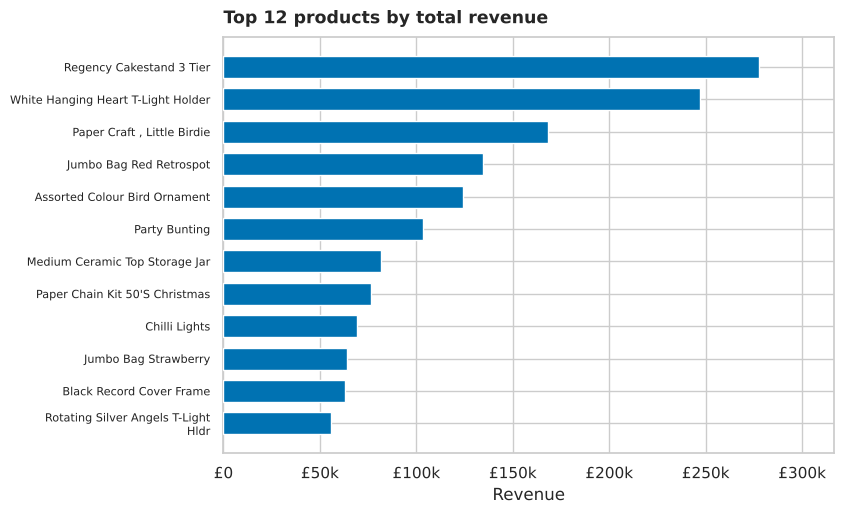

In [11]:
tp=df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(12)[::-1]
fig,ax=make_fig("Top 12 products by total revenue","Across the cleaned two-year window.",figsize=(8.6,5.3))
ax.barh(np.arange(len(tp)),tp.values,color=ACCENT,height=0.68,zorder=3)
ax.set_yticks(np.arange(len(tp))); ax.set_yticklabels([textwrap.fill(s.title(),34) for s in tp.index],fontsize=8.1,color=INK)
ax.xaxis.set_major_formatter(FuncFormatter(gbp)); ax.set_xlim(0,tp.max()*1.14); ax.set_xlabel("Revenue")
save_show(fig,"05_top_products.png")

## 5. Feature engineering: RFM
We build customer-level **RFM** features. These capture the three behaviours a retention team acts on, from domain
knowledge rather than from the algorithm: **Recency** (days since last order), **Frequency** (distinct orders),
**Monetary** (total revenue). Recency uses a fixed snapshot (last date + 1 day) so the numbers are stable.

In [12]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda s:(snapshot-s.max()).days),
    Frequency=("Invoice","nunique"), Monetary=("Revenue","sum"),
    FirstPurchase=("InvoiceDate","min"), LastPurchase=("InvoiceDate","max")).reset_index()
rfm["AOV"]=rfm["Monetary"]/rfm["Frequency"]; rfm["TenureDays"]=(rfm["LastPurchase"]-rfm["FirstPurchase"]).dt.days
print("Snapshot date:", snapshot.date(), "| customers:", len(rfm))
rfm[["Recency","Frequency","Monetary","AOV","TenureDays"]].describe().round(1)

Snapshot date: 2011-12-10 | customers: 5852


,Recency,Frequency,Monetary,AOV,TenureDays
count,5852.0,5852.0,5852.0,5852.0,5852.0
mean,200.2,6.3,2916.7,384.4,273.4
std,208.5,12.7,14306.9,1254.7,258.5
min,1.0,1.0,3.0,3.0,0.0
25%,25.0,1.0,339.6,176.1,0.0
50%,95.0,3.0,856.0,277.9,222.5
75%,379.0,7.0,2241.0,410.6,511.0
max,739.0,373.0,580987.0,84236.2,738.0


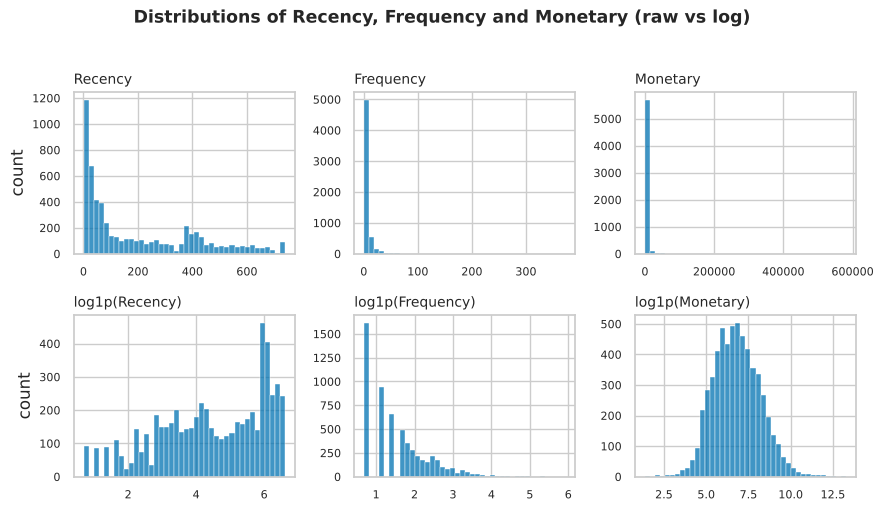

In [13]:
fig,axes=plt.subplots(2,3,figsize=(9.0,5.2))
fig.suptitle("Distributions of Recency, Frequency and Monetary (raw vs log)",fontsize=12.5,fontweight="bold")
for j,col in enumerate(["Recency","Frequency","Monetary"]):
    for i,(d,tag) in enumerate([(rfm[col],col),(np.log1p(rfm[col]),f"log1p({col})")]):
        a=axes[i,j]; sns.histplot(d,bins=40,color=ACCENT,edgecolor="white",linewidth=0.3,ax=a)
        a.set_title(tag,fontsize=10,loc="left"); a.set_xlabel(""); a.set_ylabel("count" if j==0 else ""); a.tick_params(labelsize=8)
fig.tight_layout(rect=[0,0,1,0.96])
fig.savefig(os.path.join(FIGDIR,"06_rfm_distributions.png"),dpi=150,bbox_inches="tight"); plt.show()

**Do extra features help?** Average Order Value and Tenure are both *derived from* R, F and M, so they add little
independent signal. We confirm with the silhouette score at k=4.

In [14]:
def sil_for(features,k=4):
    Xs=StandardScaler().fit_transform(np.log1p(rfm[features].values.astype(float)))
    km=KMeans(n_clusters=k,random_state=RNG,n_init=10).fit(Xs)
    return silhouette_score(Xs,km.labels_,sample_size=4000,random_state=RNG)
tests={f:round(float(sil_for(c)),3) for f,c in {
    "RFM":["Recency","Frequency","Monetary"], "RFM+AOV":["Recency","Frequency","Monetary","AOV"],
    "RFM+Tenure":["Recency","Frequency","Monetary","TenureDays"],
    "RFM+AOV+Tenure":["Recency","Frequency","Monetary","AOV","TenureDays"]}.items()}
print(tests)
print("AOV lowers separation; Tenure raises it only ~0.02 (within the noise of a 4k-subsample silhouette).")
print("Both are collinear with R/F/M, so we keep the parsimonious, business-legible RFM frame the brief calls for.")
FEATURES=["Recency","Frequency","Monetary"]

{'RFM': 0.365, 'RFM+AOV': 0.28, 'RFM+Tenure': 0.387, 'RFM+AOV+Tenure': 0.309}
AOV lowers separation; Tenure raises it only ~0.02 (within the noise of a 4k-subsample silhouette).
Both are collinear with R/F/M, so we keep the parsimonious, business-legible RFM frame the brief calls for.


## 6. A transparent baseline: RFM quartile scoring
Before K-Means we score each customer 1-4 on R, F and M by quartile. This needs no model; K-Means then has to earn
its place by finding structure this rule misses (we test that in Section 8).

In [15]:
q=rfm.copy()
q["R_s"]=pd.qcut(q["Recency"],4,labels=[4,3,2,1]).astype(int)
q["F_s"]=pd.qcut(q["Frequency"].rank(method="first"),4,labels=[1,2,3,4]).astype(int)
q["M_s"]=pd.qcut(q["Monetary"],4,labels=[1,2,3,4]).astype(int)
q["RFM_sum"]=q[["R_s","F_s","M_s"]].sum(axis=1)
print("RFM score distribution (3 = weakest, 12 = strongest):"); print(q["RFM_sum"].value_counts().sort_index())

RFM score distribution (3 = weakest, 12 = strongest):
RFM_sum
3     558
4     582
5     593
6     615
7     605
8     612
9     566
10    552
11    525
12    644
Name: count, dtype: int64


## 7. K-Means: choosing the number of clusters
Two steps Prof. Yan stressed: **standardize first** (otherwise Monetary dominates the distance), and read the
**elbow** on SSE (SSE always falls as k grows). We add the **silhouette** as a second opinion, and are honest about
what it says.

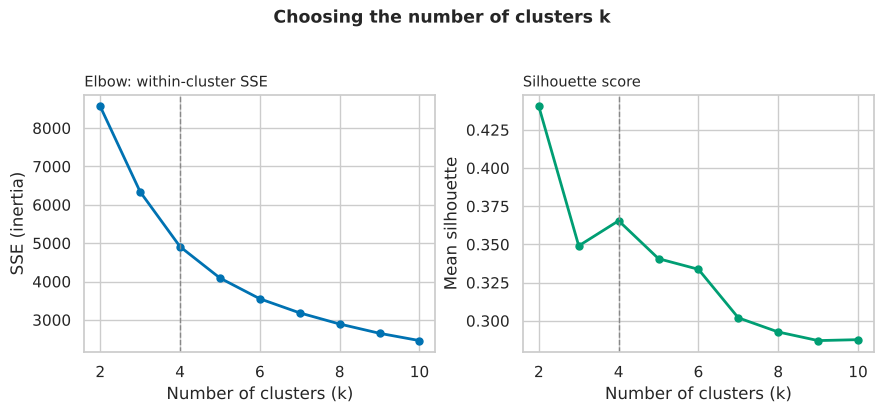

Silhouette by k: {2: 0.44, 3: 0.349, 4: 0.365, 5: 0.341, 6: 0.334, 7: 0.302, 8: 0.293, 9: 0.287, 10: 0.288}
Silhouette is HIGHEST at k=2 (0.440) but a two-way split is only 'engaged vs lapsed' - too coarse to act on.
The elbow is soft; we choose k=4 for four actionable segments. Silhouette at k=4 = 0.365 (moderate separation).


In [16]:
scaler=StandardScaler().fit(np.log1p(rfm[FEATURES].values.astype(float)))
Xs=scaler.transform(np.log1p(rfm[FEATURES].values.astype(float)))
ks=list(range(2,11)); inertia=[]; sils=[]
for k in ks:
    km=KMeans(n_clusters=k,random_state=RNG,n_init=10).fit(Xs)
    inertia.append(km.inertia_); sils.append(silhouette_score(Xs,km.labels_,sample_size=4000,random_state=RNG))
K=4
fig,(a1,a2)=plt.subplots(1,2,figsize=(9.0,4.2))
fig.suptitle("Choosing the number of clusters k",fontsize=12.5,fontweight="bold")
a1.plot(ks,inertia,color=ACCENT,lw=2,marker="o",ms=5); a1.axvline(K,color=MUTED,lw=1,ls="--")
a1.set_title("Elbow: within-cluster SSE",fontsize=10.5,loc="left"); a1.set_xlabel("Number of clusters (k)"); a1.set_ylabel("SSE (inertia)")
a2.plot(ks,sils,color=CL[2],lw=2,marker="o",ms=5); a2.axvline(K,color=MUTED,lw=1,ls="--")
a2.set_title("Silhouette score",fontsize=10.5,loc="left"); a2.set_xlabel("Number of clusters (k)"); a2.set_ylabel("Mean silhouette")
fig.tight_layout(rect=[0,0,1,0.95])
fig.savefig(os.path.join(FIGDIR,"07_kmeans_selection.png"),dpi=150,bbox_inches="tight"); plt.show()
print("Silhouette by k:", {k:round(s,3) for k,s in zip(ks,sils)})
print(f"Silhouette is HIGHEST at k=2 ({sils[0]:.3f}) but a two-way split is only 'engaged vs lapsed' - too coarse to act on.")
print(f"The elbow is soft; we choose k=4 for four actionable segments. Silhouette at k=4 = {sils[2]:.3f} (moderate separation).")

## 8. Final model, segment profiling and personas
We wrap the log-transform, scaler and K-Means into one `Pipeline` so the identical steps apply to any new customer.
The clusters are only a starting point; naming and interpreting them is the real work, done by reading each profile.

In [17]:
pipe=Pipeline([("log",FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
               ("scale",StandardScaler()),("kmeans",KMeans(n_clusters=K,random_state=RNG,n_init=10))])
pipe.fit(rfm[FEATURES]); rfm["Cluster"]=pipe.named_steps["kmeans"].labels_
prof=rfm.groupby("Cluster").agg(n=("Customer ID","size"),
    Recency_med=("Recency","median"),Frequency_med=("Frequency","median"),
    Monetary_med=("Monetary","median"),Monetary_sum=("Monetary","sum"),AOV_med=("AOV","median")).reset_index()
prof["pct_customers"]=(prof["n"]/prof["n"].sum()*100).round(1)
prof["pct_revenue"]=(prof["Monetary_sum"]/prof["Monetary_sum"].sum()*100).round(1)
# Read the profile: best-on-all = Champions, worst-on-all = Hibernating; of the rest, the lapsed (higher recency) is At-Risk.
def _z(s): s=s.astype(float); sd=s.std(ddof=0); return (s-s.mean())/(sd if sd else 1.0)
prof["composite"]=-_z(prof["Recency_med"])+_z(prof["Frequency_med"])+_z(prof["Monetary_med"])
champ=prof["composite"].idxmax(); hib=prof["composite"].idxmin()
rest=sorted([i for i in prof.index if i not in (champ,hib)], key=lambda i: prof.loc[i,"Recency_med"])
names={champ:"Champions", hib:"Hibernating / Low-Value", rest[0]:"Loyal / Promising", rest[-1]:"At-Risk / Need Attention"}
prof["Persona"]=prof.index.map(names)
cmap={int(r.Cluster):r.Persona for r in prof.itertuples()}; rfm["Persona"]=rfm["Cluster"].map(cmap)
display(prof[["Cluster","Persona","n","pct_customers","Recency_med","Frequency_med","Monetary_med","AOV_med","pct_revenue"]])

,Cluster,Persona,n,pct_customers,Recency_med,Frequency_med,Monetary_med,AOV_med,pct_revenue
0,0,At-Risk / Need Attention,1455,24.9,184.0,4.0,1455.270,320.633333,16.9
1,1,Champions,1182,20.2,16.0,13.0,4904.980,365.582738,73.3
2,2,Hibernating / Low-Value,1969,33.6,401.0,1.0,275.880,200.470000,3.7
3,3,Loyal / Promising,1246,21.3,24.0,3.0,720.355,255.112000,6.1


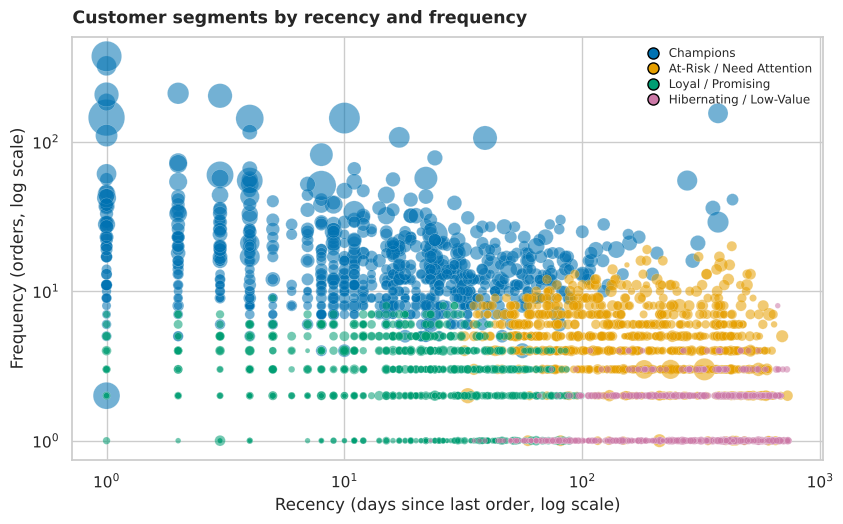

In [18]:
order=prof.sort_values("Monetary_med",ascending=False)["Cluster"].tolist(); cfor={c:CL[i] for i,c in enumerate(order)}
fig,ax=make_fig("Customer segments by recency and frequency","Each point is a customer; marker size is total spend. Both axes use a log scale.",figsize=(8.6,5.4))
s=rfm.sample(min(4000,len(rfm)),random_state=RNG)
for c in order:
    g=s[s["Cluster"]==c]; ax.scatter(g["Recency"],g["Frequency"],s=np.sqrt(g["Monetary"])*0.9+4,color=cfor[c],alpha=0.55,edgecolor="white",linewidth=0.2,label=cmap[c],zorder=3)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Recency (days since last order, log scale)"); ax.set_ylabel("Frequency (orders, log scale)")
from matplotlib.lines import Line2D
handles=[Line2D([0],[0],marker="o",color="none",markerfacecolor=cfor[c],markersize=8,label=cmap[c]) for c in order]
ax.legend(handles=handles, loc="upper right", frameon=False, fontsize=8.6, handletextpad=0.3, labelspacing=0.3)
save_show(fig,"08_cluster_scatter.png")

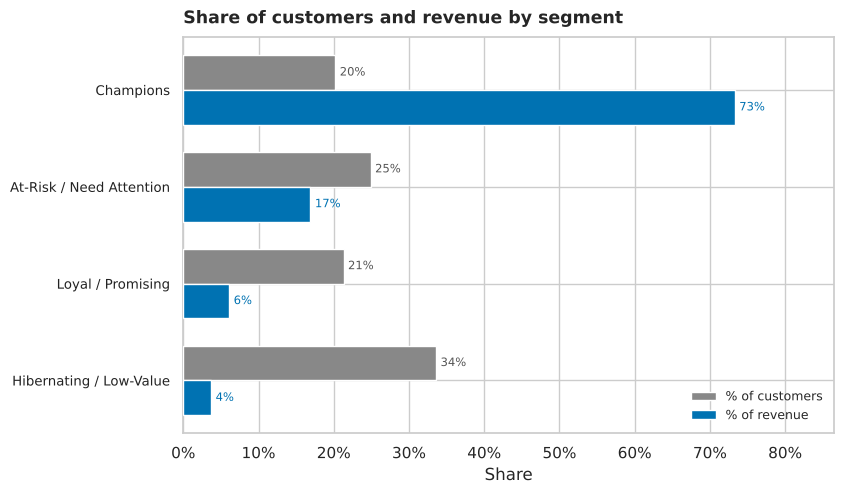

In [19]:
po=prof.set_index("Persona").loc[[cmap[c] for c in order]]
fig,ax=make_fig("Share of customers and revenue by segment","Grey bars: share of customers. Blue bars: share of revenue.",figsize=(8.6,5.1))
yp=np.arange(len(po))[::-1]; h=0.36
ax.barh(yp+h/2,po["pct_customers"],height=h,color=MUTED,zorder=3,label="% of customers")
ax.barh(yp-h/2,po["pct_revenue"],height=h,color=ACCENT,zorder=3,label="% of revenue")
ax.set_yticks(yp); ax.set_yticklabels(po.index,fontsize=9.6,color=INK); ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_:f"{x:.0f}%"))
for i,(cu,re_) in enumerate(zip(po["pct_customers"],po["pct_revenue"])):
    ax.text(cu+0.6,yp[i]+h/2,f"{cu:.0f}%",va="center",fontsize=8.3,color=INK2); ax.text(re_+0.6,yp[i]-h/2,f"{re_:.0f}%",va="center",fontsize=8.3,color=ACCENT)
ax.legend(loc="lower right",frameon=False,fontsize=9); ax.set_xlim(0,po[["pct_customers","pct_revenue"]].values.max()*1.18); ax.set_xlabel("Share")
save_show(fig,"09_segment_customers_vs_revenue.png")

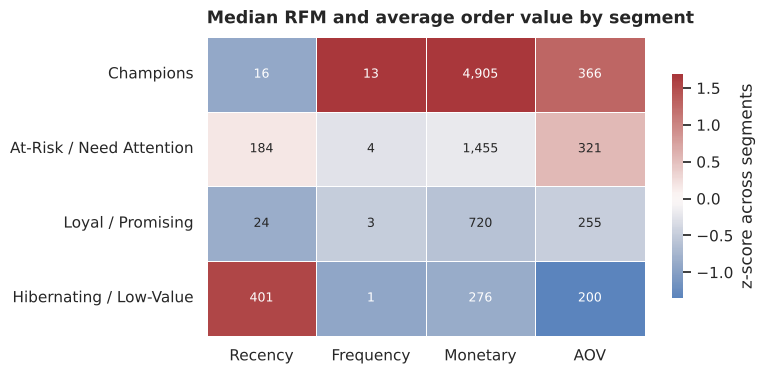

In [20]:
zcols=["Recency","Frequency","Monetary","AOV"]
zmed=rfm.groupby("Persona")[zcols].median().loc[[cmap[c] for c in order]]; z=(zmed-zmed.mean())/zmed.std(ddof=0)
fig,ax=plt.subplots(figsize=(7.8,3.9))
sns.heatmap(z,annot=zmed.values,fmt=",.0f",cmap="vlag",center=0,linewidths=0.6,linecolor="white",
            cbar_kws={"shrink":0.75,"label":"z-score across segments"},annot_kws={"fontsize":9},ax=ax)
ax.set_title("Median RFM and average order value by segment",fontsize=12.5,fontweight="bold",loc="left",pad=10)
ax.set_xlabel(""); ax.set_ylabel(""); plt.setp(ax.get_yticklabels(),rotation=0); plt.setp(ax.get_xticklabels(),rotation=0)
save_show(fig,"10_segment_profile_heatmap.png")

**Reading the four clusters (interpretation, not a rule):**

- **Champions** (~20% of customers, ~73% of revenue): most recent, most frequent, highest spend. *Protect, do not discount.*
- **At-Risk / Need Attention** (~25%, ~17%): were valuable (median 4 orders, ~£1,455) but last bought ~6 months ago. *Win them back now.*
- **Loyal / Promising** (~21%, ~6%): recent but small baskets and low frequency. *Grow basket size via bundles and cross-sell.*
- **Hibernating / Low-Value** (~34%, ~4%): one-off buyers, inactive >1 year, lowest value. *Reach only via the cheapest channels.*

Note that Champions and At-Risk have *similar* average order value, so what separates them is recency and frequency, not basket size, which is exactly what a win-back can move.

## 8b. Checking the model
A model should beat the simple baseline and not depend on luck. We test three things: does K-Means find structure the
quartile score misses, are the clusters stable, and were we right to delete returns rather than net them?

In [21]:
# (a) Baseline vs K-Means: agreement + where the simple rule fails
qt=pd.cut(q["RFM_sum"],bins=[2,5,9,12],labels=["Low (3-5)","Mid (6-9)","High (10-12)"])
qm=rfm[["Customer ID","Persona"]].merge(pd.DataFrame({"Customer ID":q["Customer ID"].values,"tier":qt.values}),on="Customer ID")
display(pd.crosstab(qm["Persona"],qm["tier"]))
print("Adjusted Rand index, baseline score vs K-Means clusters:", round(adjusted_rand_score(q["RFM_sum"].astype(str), rfm["Cluster"].astype(str)),3), "(low => K-Means adds real structure)")
ar=(qm[qm["Persona"].str.startswith("At-Risk")]["tier"].value_counts(normalize=True)*100).round(1)
print("The At-Risk cluster by baseline tier (%):", ar.to_dict(), "-> a plain quartile cut buries them in the middle.")

tier,Low (3-5),Mid (6-9),High (10-12)
Persona,,,
At-Risk / Need Attention,23,1156,276
Champions,0,3,1179
Hibernating / Low-Value,1664,305,0
Loyal / Promising,46,934,266


Adjusted Rand index, baseline score vs K-Means clusters: 0.266 (low => K-Means adds real structure)
The At-Risk cluster by baseline tier (%): {'Mid (6-9)': 79.5, 'High (10-12)': 19.0, 'Low (3-5)': 1.6} -> a plain quartile cut buries them in the middle.


In [22]:
# (b) Stability: ARI across 10 random initializations, and after dropping the top 1% of spenders
Xfit=pipe.named_steps["scale"].transform(pipe.named_steps["log"].transform(rfm[FEATURES])); ref=rfm["Cluster"].values
aris=[adjusted_rand_score(ref,KMeans(n_clusters=K,random_state=sd,n_init=10).fit_predict(Xfit)) for sd in range(10)]
print(f"Stability across 10 seeds: mean ARI={np.mean(aris):.3f}, min={np.min(aris):.3f} (near 1 = very stable).")
thr=rfm["Monetary"].quantile(0.99); core=rfm[rfm["Monetary"]<=thr]
Xc=StandardScaler().fit_transform(np.log1p(core[FEATURES].values.astype(float)))
print(f"Drop top-1% spenders and re-cluster: ARI={adjusted_rand_score(rfm.loc[core.index,'Cluster'].values, KMeans(n_clusters=K,random_state=RNG,n_init=10).fit_predict(Xc)):.3f} (robust to outliers).")

Stability across 10 seeds: mean ARI=0.997, min=0.992 (near 1 = very stable).
Drop top-1% spenders and re-cluster: ARI=0.913 (robust to outliers).


In [23]:
# (c) Returns: would netting returns (instead of deleting cancellations) change the segments?
cmask=raw["Invoice"].str.startswith("C").fillna(False) & raw["StockCode"].str.match(r"^\d{5}[A-Za-z]*$").fillna(False)
tmp=raw.loc[cmask & raw["Customer ID"].notna()].copy(); tmp["rv"]=tmp["Quantity"].abs()*tmp["Price"].abs()
ret=tmp.groupby(tmp["Customer ID"].astype(int))["rv"].sum()
mg=rfm[["Customer ID","Monetary","Persona"]].merge(ret.rename("ReturnVal"),left_on="Customer ID",right_index=True,how="left")
mg["ReturnVal"]=mg["ReturnVal"].fillna(0.0); mg["ratio"]=mg["ReturnVal"]/(mg["Monetary"]+mg["ReturnVal"])
print(f"Customers with any return: {ret.shape[0]:,} ({ret.shape[0]/len(rfm)*100:.1f}%)  | total gross returns £{tmp['rv'].sum():,.0f}")
print(f"Material returns (>20% of gross spend): {(mg['ratio']>0.2).sum()} customers, "
      f"of which Champions: {((mg['Persona']=='Champions')&(mg['ratio']>0.2)).sum()} -> netting would not meaningfully move the segments.")

Customers with any return: 2,444 (41.8%)  | total gross returns £719,653
Material returns (>20% of gross spend): 100 customers, of which Champions: 7 -> netting would not meaningfully move the segments.


## 9. Market basket analysis (bonus)
We ask *what sells with what* on UK orders, ranking rules by **lift** (not confidence): lift > 1 means a pair is
bought together more than chance. Lift is symmetric, so we keep one row per pair, and we also look below the top
tier for genuinely cross-category rules.

In [24]:
from mlxtend.frequent_patterns import apriori, association_rules
uk=df[df["Country"]=="United Kingdom"]; top=uk["Description"].value_counts().head(300).index
b=uk[uk["Description"].isin(top)]
basket=(b.groupby(["Invoice","Description"])["Quantity"].sum().unstack().fillna(0)>0); basket=basket[basket.sum(axis=1)>=2]
allr=association_rules(apriori(basket,min_support=0.015,use_colnames=True,max_len=2),metric="lift",min_threshold=1.0)
allr=allr[allr["confidence"]>=0.3].sort_values("lift",ascending=False)
seen=set(); rows=[]
for r in allr.itertuples():
    p=frozenset(set(r.antecedents)|set(r.consequents))
    if p in seen: continue
    seen.add(p); rows.append((", ".join(r.antecedents),", ".join(r.consequents),round(r.support,3),round(r.confidence,3),round(r.lift,2)))
rules=pd.DataFrame(rows,columns=["antecedent","consequent","support","confidence","lift"])
print(f"Baskets analysed: {len(basket):,} | unique rules: {len(rules)}")
display(rules.head(10))

Baskets analysed: 26,403 | unique rules: 96


,antecedent,consequent,support,confidence,lift
0,"KEY FOB , BACK DOOR","KEY FOB , SHED",0.016,0.730,29.86
1,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.017,0.718,28.15
2,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.021,0.667,26.91
3,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,0.016,0.657,26.85
4,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.017,0.733,26.11
5,BATHROOM METAL SIGN,KITCHEN METAL SIGN,0.016,0.467,23.75
6,ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.020,0.578,23.32
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.025,0.722,23.14
8,BATHROOM METAL SIGN,TOILET METAL SIGN,0.021,0.612,22.88
9,FELTCRAFT CUSHION RABBIT,FELTCRAFT CUSHION OWL,0.015,0.618,22.46


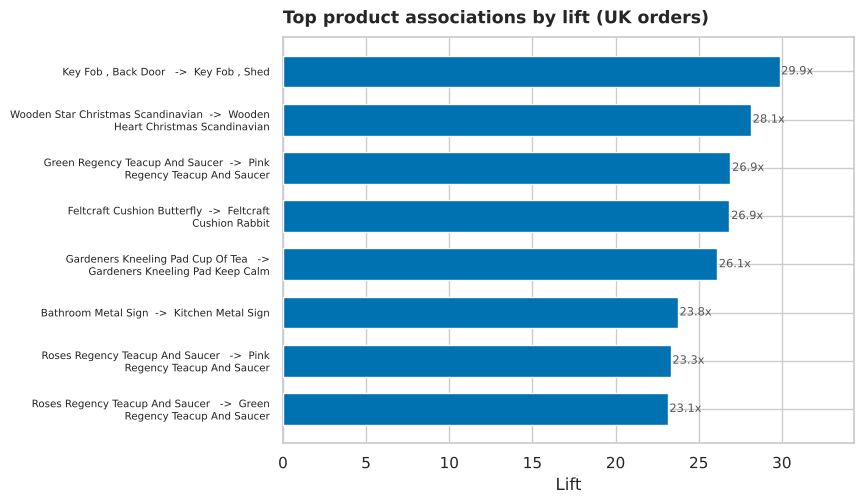

In [25]:
rr=rules.head(8)[::-1]
fig,ax=make_fig("Top product associations by lift (UK orders)","Lift above 1 means the pair is bought together more often than chance. Mirror rules removed.",figsize=(8.8,5.2))
labels=[textwrap.fill(f"{a.title()}  ->  {c.title()}",46) for a,c in zip(rr["antecedent"],rr["consequent"])]
ax.barh(np.arange(len(rr)),rr["lift"].values,color=ACCENT,height=0.66,zorder=3)
ax.set_yticks(np.arange(len(rr))); ax.set_yticklabels(labels,fontsize=7.4,color=INK)
for i,v in enumerate(rr["lift"].values): ax.text(v+0.1,i,f"{v:.1f}x",va="center",fontsize=8.2,color=INK2)
ax.set_xlim(0,rr["lift"].max()*1.15); ax.set_xlabel("Lift")
save_show(fig,"11_market_basket.png")

The strongest associations are **variant completions within a line** (colour variants of the same teacup, matching
Christmas decorations), which support "complete the set" prompts. The deliverable is the translation: these pairs are
ready-made for bundling and *frequently bought together* placement. Lowering the support threshold also surfaces
genuinely **cross-category** rules (for example a decorative word block with a hanging-heart t-light holder), which
point to home-decor cross-sell rather than mere set completion.

## 10. Export the model and run a test case
We persist the full pipeline and show it classifying a new customer end-to-end.

In [26]:
joblib.dump(pipe, os.path.join(MODELDIR,"segmentation_pipeline.joblib"))
json.dump({str(k):v for k,v in cmap.items()}, open(os.path.join(MODELDIR,"cluster_personas.json"),"w"), indent=2)
rfm[["Customer ID","Recency","Frequency","Monetary","AOV","TenureDays","Cluster","Persona"]].to_csv(os.path.join(DATADIR,"customer_rfm_segments.csv"), index=False)
model=joblib.load(os.path.join(MODELDIR,"segmentation_pipeline.joblib")); personas=json.load(open(os.path.join(MODELDIR,"cluster_personas.json")))
test=pd.DataFrame([{"Recency":12,"Frequency":15,"Monetary":6000.0}])
pred=int(model.predict(test)[0])
print("Test customer:", test.to_dict("records")[0]); print("Predicted cluster:", pred, "->", personas[str(pred)])

Test customer: {'Recency': 12, 'Frequency': 15, 'Monetary': 6000.0}
Predicted cluster: 1 -> Champions


## 11. Limitations: what this data cannot tell us
- **A fifth of transactions have no Customer ID** (~13% of revenue). Segmentation covers only identifiable customers.
- **No cost or margin data**, so "value" means revenue, not profit. A high-revenue segment is not automatically high-profit.
- **No browsing, marketing-spend, or return-reason data**, so we see *what* happened, not *why*, and cannot attribute sales to campaigns.
- **UK-dominated** (~84% of revenue): patterns should not be generalized to other markets.
- **One retailer, one category (gifts/homeware), 2009-2011**: findings are specific and dated.
- **Clusters describe behaviour, they do not explain it**, and the silhouette (0.37) shows the separation is moderate, so the segments are a decision aid, not ground truth. They are, however, stable across initializations and to outlier removal (Section 8b).

## 12. Conclusion
A disciplined clean took 1.07M messy rows to ~777k reliable transactions. RFM plus K-Means (k=4) splits 5,852
customers into four segments that each demand a different action, and the concentration is stark: **Champions are
~20% of customers but ~73% of revenue**. Retention spend should weight heavily toward them, with a targeted win-back
on the At-Risk group (~£2.9M of historic revenue) and cheap-channel-only treatment for the Hibernating group. The
market-basket rules add concrete cross-sell pairs. The honest caveat is that this is a behavioural, revenue-only view
of one UK retailer, so it should steer experiments, not replace them.